In [ ]:
#Assignment 1:
#BUSINESS PROBLEM
'''Business Objective

The airline company wants to segment customers based on their flying history and loyalty card information to improve customer retention, personalized marketing, and reward programs.'''

#Constraints
'''Data contains customers with different scales of values.
Outliers may affect clustering.
Need to identify optimal number of clusters.'''

'Data contains customers with different scales of values.\nOutliers may affect clustering.\nNeed to identify optimal number of clusters.'

In [ ]:
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import LabelEncoder

# Hierarchical Clustering
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# Evaluation
from sklearn.metrics import silhouette_score

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
airline = pd.read_excel('EastWestAirlines.xlsx')

# Display first 5 rows
airline.head()

,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [ ]:
print("Shape of Dataset:", airline.shape)
airline.info()
airline.describe()

Shape of Dataset: (3999, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
count,3999.000000,3.999000e+03,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000,3999.00000,3999.000000,3999.000000,3999.00000,3999.000000
mean,2014.819455,7.360133e+04,144.114529,2.059515,1.014504,1.012253,17144.846212,11.60190,460.055764,1.373593,4118.55939,0.370343
std,1160.764358,1.007757e+05,773.663804,1.376919,0.147650,0.195241,24150.967826,9.60381,1400.209171,3.793172,2065.13454,0.482957
min,1.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,0.000000,0.00000,0.000000,0.000000,2.00000,0.000000
25%,1010.500000,1.852750e+04,0.000000,1.000000,1.000000,1.000000,1250.000000,3.00000,0.000000,0.000000,2330.00000,0.000000
50%,2016.000000,4.309700e+04,0.000000,1.000000,1.000000,1.000000,7171.000000,12.00000,0.000000,0.000000,4096.00000,0.000000
75%,3020.500000,9.240400e+04,0.000000,3.000000,1.000000,1.000000,23800.500000,17.00000,311.000000,1.000000,5790.50000,1.000000
max,4021.000000,1.704838e+06,11148.000000,5.000000,3.000000,5.000000,263685.000000,86.00000,30817.000000,53.000000,8296.00000,1.000000


In [ ]:
#data dict
airline.columns

Index(['ID#', 'Balance', 'Qual_miles', 'cc1_miles', 'cc2_miles', 'cc3_miles',
       'Bonus_miles', 'Bonus_trans', 'Flight_miles_12mo', 'Flight_trans_12',
       'Days_since_enroll', 'Award?'],
      dtype='object')

In [ ]:
'''Feature	          Description
   Balance	          Number of miles eligible for award travel
   Qual_miles	        Qualifying miles earned
   cc1_miles	        Credit card miles category
   Bonus_miles        Bonus miles earned
   Flight_miles_12mo	Flight miles in last 12 months
   Award	            Award status'''

'Feature\t          Description\n   Balance\t          Number of miles eligible for award travel\n   Qual_miles\t        Qualifying miles earned\n   cc1_miles\t        Credit card miles category\n   Bonus_miles        Bonus miles earned\n   Flight_miles_12mo\tFlight miles in last 12 months\n   Award\t            Award status'

In [ ]:
#missing val
airline.isnull().sum()

,0
ID#,0
Balance,0
Qual_miles,0
cc1_miles,0
cc2_miles,0
cc3_miles,0
Bonus_miles,0
Bonus_trans,0
Flight_miles_12mo,0
Flight_trans_12,0


In [ ]:
#dupliate val
# Check duplicates
airline.duplicated().sum()

# Remove duplicates
airline = airline.drop_duplicates()

In [ ]:
#EDA
airline.describe().T

,count,mean,std,min,25%,50%,75%,max
ID#,3999.0,2014.819455,1160.764358,1.0,1010.5,2016.0,3020.5,4021.0
Balance,3999.0,73601.327582,100775.664958,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.114529,773.663804,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.059515,1.376919,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.014504,0.147650,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.012253,0.195241,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.846212,24150.967826,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.601900,9.603810,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.055764,1400.209171,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.373593,3.793172,0.0,0.0,0.0,1.0,53.0


In [ ]:
#1MBD
airline.mean(numeric_only=True)

#2MBD
airline.var(numeric_only=True)

#3MBD
airline.skew(numeric_only=True)

#4MBD
airline.kurt(numeric_only=True)

,0
ID#,-1.199648
Balance,44.157932
Qual_miles,67.689351
cc1_miles,-0.748508
cc2_miles,133.786489
cc3_miles,308.654728
Bonus_miles,13.630489
Bonus_trans,2.745737
Flight_miles_12mo,94.761019
Flight_trans_12,42.978152


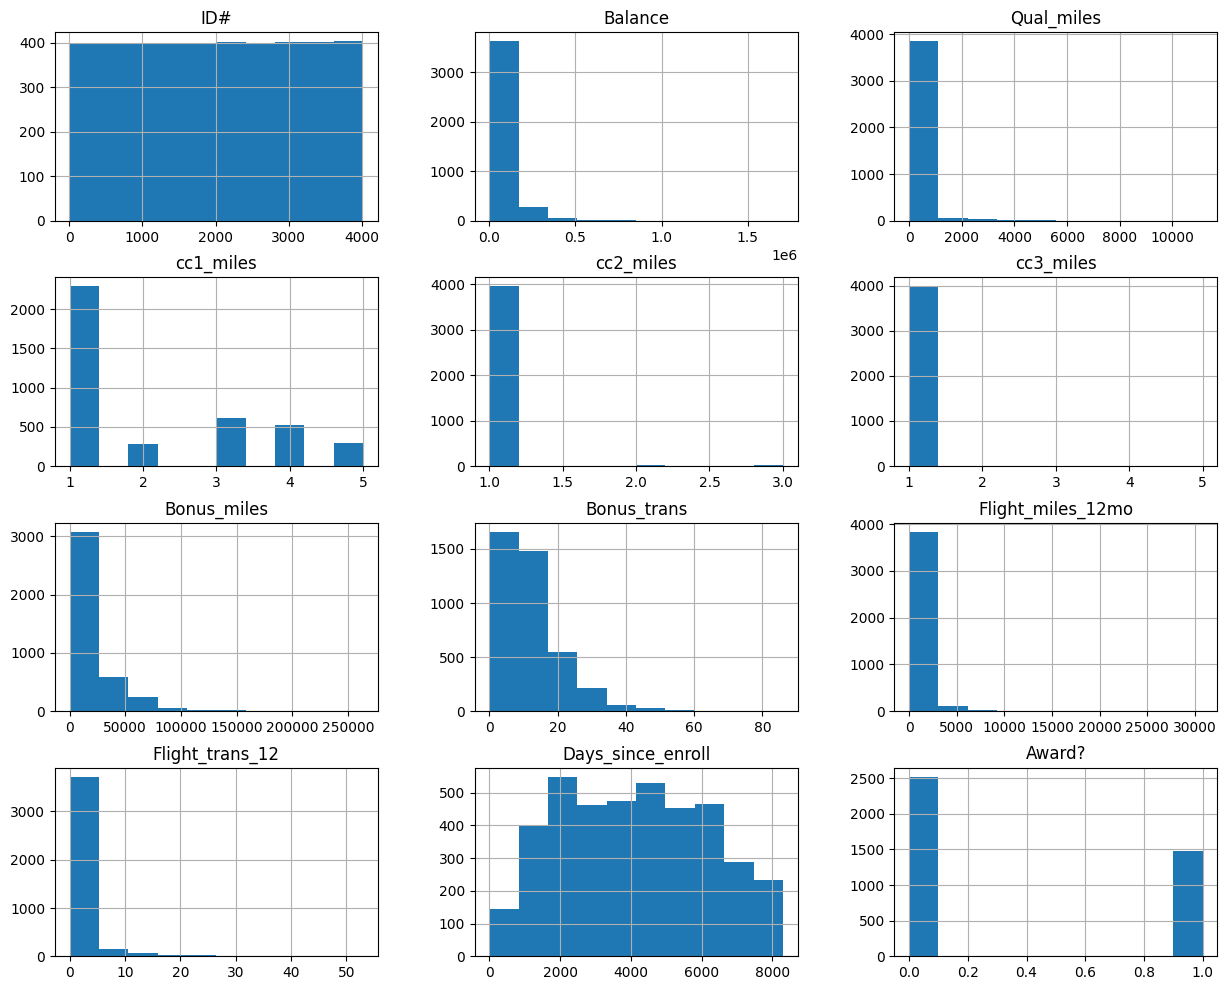

In [ ]:
#univariate analysis
airline.hist(figsize=(15,12))
plt.show()

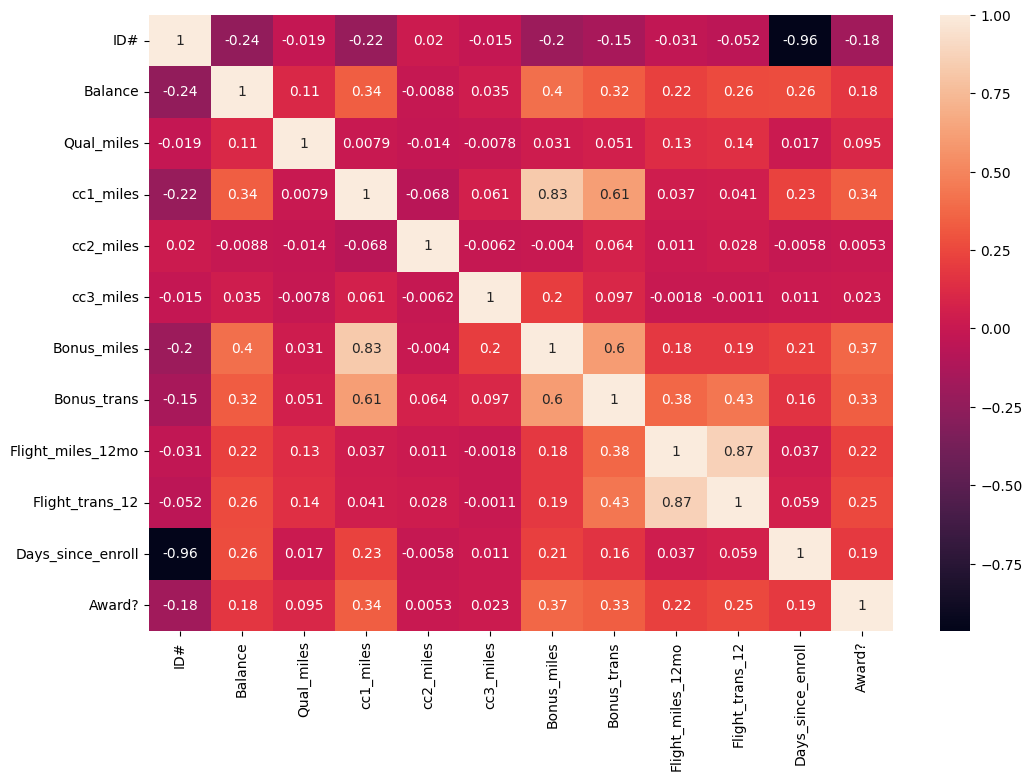

In [ ]:
#correlation
plt.figure(figsize=(12,8))

sns.heatmap(
airline.corr(numeric_only=True),
annot=True
)

plt.show()

In [ ]:
#preprocessing
df=airline.drop('ID#',axis=1)

scaler=StandardScaler()

scaled=scaler.fit_transform(df)

scaled=pd.DataFrame(
scaled,
columns=df.columns
)

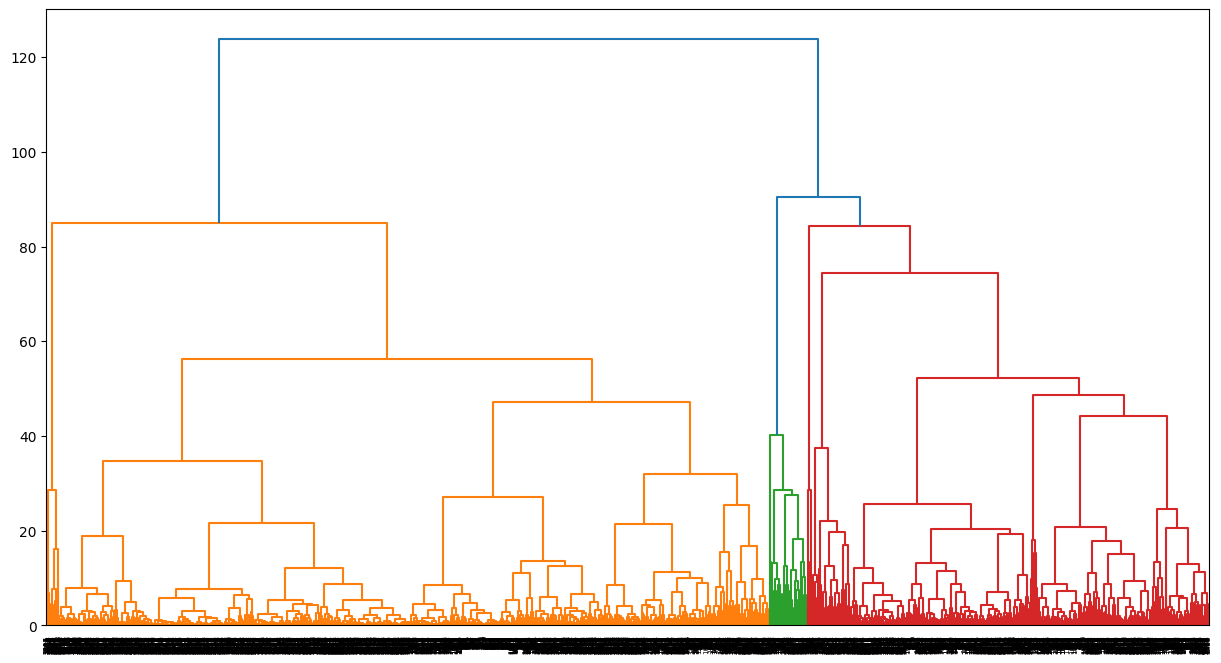

In [ ]:
#dendogram
plt.figure(figsize=(15,8))

dendrogram(
linkage(
scaled,
method='ward'
)
)

plt.show()

In [ ]:
#model building
scores=[]

for k in range(2,10):

 model=AgglomerativeClustering(
 n_clusters=k,
 linkage='ward'
 )

 pred=model.fit_predict(scaled)

 score=silhouette_score(
 scaled,
 pred
 )

 scores.append(score)

print(scores)

[np.float64(0.28926595242577247), np.float64(0.2940432062008608), np.float64(0.30814152852022786), np.float64(0.3098805307874414), np.float64(0.3192511970153055), np.float64(0.18965334676868836), np.float64(0.1890586470843928), np.float64(0.1951894366329298)]


In [ ]:
#final model
model=AgglomerativeClustering(
n_clusters=4
)

cluster=model.fit_predict(scaled)

df['Cluster']=cluster

df.head()

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,Cluster
0,28143,0,1,1,1,174,1,0,0,7000,0,1
1,19244,0,1,1,1,215,2,0,0,6968,0,1
2,41354,0,1,1,1,4123,4,0,0,7034,0,1
3,14776,0,1,1,1,500,1,0,0,6952,0,1
4,97752,0,4,1,1,43300,26,2077,4,6935,1,0


In [ ]:
#cluster interpretation
cluster_summary=df.groupby(
'Cluster'
).mean()

cluster_summary

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,,,,,,
0,116314.450725,363.839130,3.498551,1.000000,1.035507,37150.356522,18.066667,377.000000,1.150000,4696.888406,0.663043
1,46329.336877,9.028618,1.244072,1.000000,1.000000,4868.112428,6.907604,214.812756,0.673753,3769.337694,0.184383
2,134880.892308,393.323077,2.430769,1.000000,1.000000,36582.169231,29.338462,5915.523077,16.638462,4599.607692,0.753846
3,68876.581395,23.255814,1.139535,2.348837,1.000000,14689.837209,17.534884,582.627907,2.209302,3968.930233,0.395349


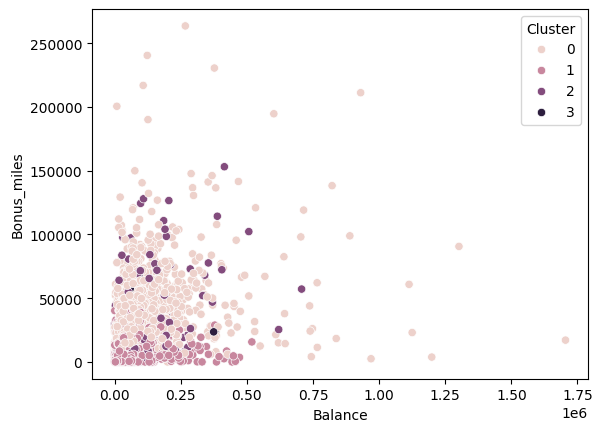

In [ ]:
#visualization
sns.scatterplot(
x='Balance',
y='Bonus_miles',
hue='Cluster',
data=df
)

plt.show()

In [ ]:
'''Business Decisions

Cluster 0 → Low engagement → promotional campaigns

Cluster 1 → Premium flyers → loyalty rewards

Cluster 2 → Frequent travelers → retention strategy

Cluster 3 → New customers → onboarding campaigns'''

'Business Decisions\n\nCluster 0 → Low engagement → promotional campaigns\n\nCluster 1 → Premium flyers → loyalty rewards\n\nCluster 2 → Frequent travelers → retention strategy\n\nCluster 3 → New customers → onboarding campaigns'

In [ ]:
#Assignment 2
crime=pd.read_csv(
'/content/crime_data.csv'
)

crime.head()

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


In [ ]:
#preprocessing
states=crime.iloc[:,0]

crime=crime.drop(
crime.columns[0],
axis=1
)

scaler=StandardScaler()

scaled=scaler.fit_transform(crime)

In [ ]:
#1MBD
crime.mean()
#2MBD
crime.var()
#3MBD
crime.skew()
#4MBD
crime.kurt()

,0
Murder,-0.827488
Assault,-1.053848
UrbanPop,-0.738360
Rape,0.353964


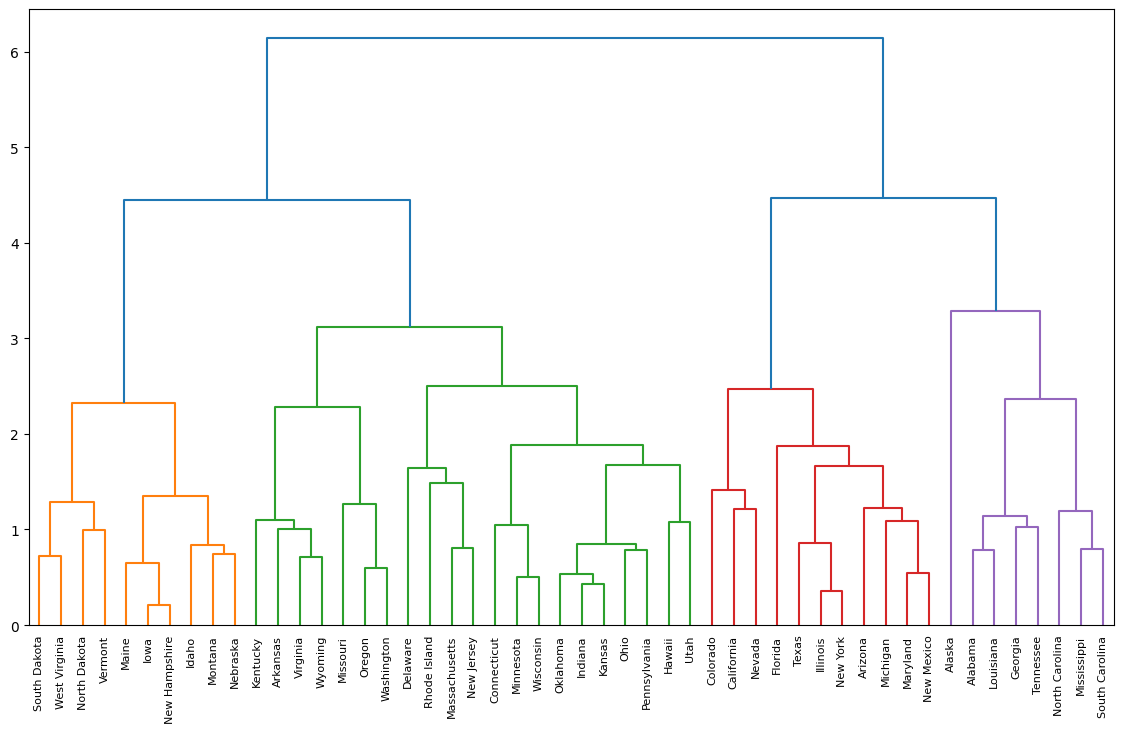

In [ ]:
#dendogram
plt.figure(figsize=(14,8))

dendrogram(
linkage(
scaled,
method='complete'
),
labels=states.values
)

plt.show()

In [ ]:
#clusering
model=AgglomerativeClustering(
n_clusters=4
)

clusters=model.fit_predict(
scaled
)

crime['Cluster']=clusters

In [ ]:
#insights
crime.groupby(
'Cluster'
).mean()

,Murder,Assault,UrbanPop,Rape
Cluster,,,,
0,6.210526,142.052632,71.263158,19.184211
1,10.966667,264.000000,76.500000,33.608333
2,3.091667,76.000000,52.083333,11.833333
3,14.671429,251.285714,54.285714,21.685714


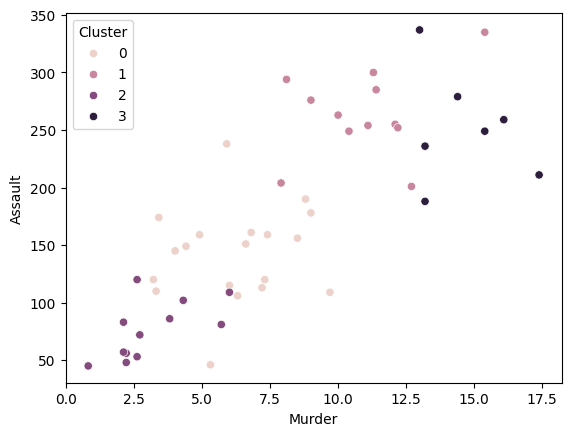

In [ ]:
#visualization
sns.scatterplot(
x='Murder',
y='Assault',
hue='Cluster',
data=crime
)

plt.show()

In [ ]:
'''Business Decisions

High Crime Cluster → More security allocation

Moderate → Prevention programs

Low → Maintain policies'''

'Business Decisions\n\nHigh Crime Cluster → More security allocation\n\nModerate → Prevention programs\n\nLow → Maintain policies'

In [ ]:
#ASSIGNMENT 3
telco=pd.read_excel(
'/content/Telco_customer_churn.xlsx'
)

In [ ]:
#preprocessing
telco=telco.drop(
'Customer ID',
axis=1
)

cat=telco.select_dtypes(
include='object'
).columns

num=telco.select_dtypes(
exclude='object'
).columns

In [ ]:
#missing val
telco[cat]=telco[
cat
].fillna(
'Unknown'
)

telco[num]=telco[
num
].fillna(
telco[num].median()
)

In [ ]:
#encoding
telco=pd.get_dummies(
telco,
drop_first=True
)

In [ ]:
#scaling
scaler=StandardScaler()

scaled=scaler.fit_transform(
telco
)

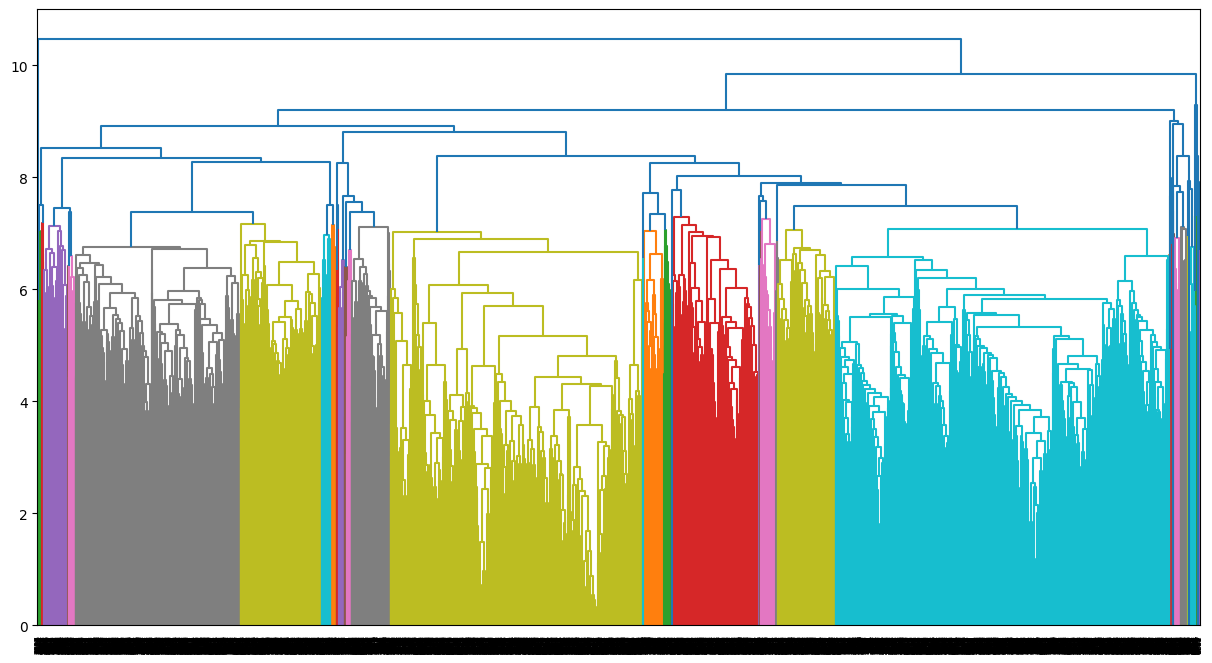

In [ ]:
#dendogram
plt.figure(
figsize=(15,8)
)

dendrogram(
linkage(
scaled,
method='average'
)
)

plt.show()

In [ ]:
#model
model=AgglomerativeClustering(
n_clusters=5
)

cluster=model.fit_predict(
scaled
)

telco['Cluster']=cluster

In [ ]:
#interpretation
telco.groupby(
'Cluster'
).mean()

,Count,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,...,Premium Tech Support_Yes,Streaming TV_Yes,Streaming Movies_Yes,Streaming Music_Yes,Unlimited Data_Yes,Contract_One Year,Contract_Two Year,Paperless Billing_Yes,Payment Method_Credit Card,Payment Method_Mailed Check
Cluster,,,,,,,,,,,,,,,,,,,,,
0,1.0,1.973856,37.384687,13.580766,26.946779,65.022129,2528.830112,1.537647,35.191410,507.725892,...,0.417367,0.507937,0.519141,0.451914,0.629318,0.281046,0.239963,0.639589,0.372549,0.020542
1,1.0,1.103201,14.411120,23.438635,24.827296,73.998736,1147.147051,3.595173,2.674810,323.594111,...,0.196714,0.364364,0.365628,0.344987,0.898905,0.067397,0.070767,0.707245,0.278012,0.001685
2,1.0,2.946504,55.702860,26.421610,27.394597,88.764062,5028.589115,0.577034,2.028602,1459.708353,...,0.570975,0.663665,0.668962,0.600106,0.941208,0.372881,0.426907,0.660487,0.403072,0.016949
3,1.0,2.217579,31.762968,24.933559,0.000000,21.114805,689.474380,1.766736,0.000000,802.974705,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.237752,0.436599,0.298271,0.669308,0.003602
4,1.0,1.158385,14.270186,21.800652,15.431677,43.201863,552.963975,0.298820,1.397516,290.251522,...,0.161491,0.139752,0.139752,0.161491,0.496894,0.170807,0.142857,0.453416,0.000000,1.000000


In [ ]:
'''Business Decisions

High Revenue : Retain

Low Tenure : Discount

High Churn Risk : Offer Plans'''

'Business Decisions\n\nHigh Revenue : Retain\n\nLow Tenure : Discount\n\nHigh Churn Risk : Offer Plans'

In [ ]:
#ASSIGNMENT 4
auto=pd.read_csv(
'/content/AutoInsurance.csv'
)

In [ ]:
#EDA
auto.info()

auto.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9134 entries, 0 to 9133
Data columns (total 24 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Customer                       9134 non-null   object 
 1   State                          9134 non-null   object 
 2   Customer Lifetime Value        9134 non-null   float64
 3   Response                       9134 non-null   object 
 4   Coverage                       9134 non-null   object 
 5   Education                      9134 non-null   object 
 6   Effective To Date              9134 non-null   object 
 7   EmploymentStatus               9134 non-null   object 
 8   Gender                         9134 non-null   object 
 9   Income                         9134 non-null   int64  
 10  Location Code                  9134 non-null   object 
 11  Marital Status                 9134 non-null   object 
 12  Monthly Premium Auto           9134 non-null   i

,Customer Lifetime Value,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount
count,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000,9134.000000
mean,8004.940475,37657.380009,93.219291,15.097000,48.064594,0.384388,2.966170,434.088794
std,6870.967608,30379.904734,34.407967,10.073257,27.905991,0.910384,2.390182,290.500092
min,1898.007675,0.000000,61.000000,0.000000,0.000000,0.000000,1.000000,0.099007
25%,3994.251794,0.000000,68.000000,6.000000,24.000000,0.000000,1.000000,272.258244
50%,5780.182197,33889.500000,83.000000,14.000000,48.000000,0.000000,2.000000,383.945434
75%,8962.167041,62320.000000,109.000000,23.000000,71.000000,0.000000,4.000000,547.514839
max,83325.381190,99981.000000,298.000000,35.000000,99.000000,5.000000,9.000000,2893.239678


In [ ]:
#converts dates
auto[
'Effective To Date'
]=pd.to_datetime(
auto[
'Effective To Date']
)

In [ ]:
#encoding
auto=pd.get_dummies(
auto,
drop_first=True
)

In [ ]:
#scaling
# Drop the 'Effective To Date' column before scaling
auto_numeric = auto.drop('Effective To Date', axis=1)

scaler=StandardScaler()

scaled=scaler.fit_transform(
auto_numeric
)

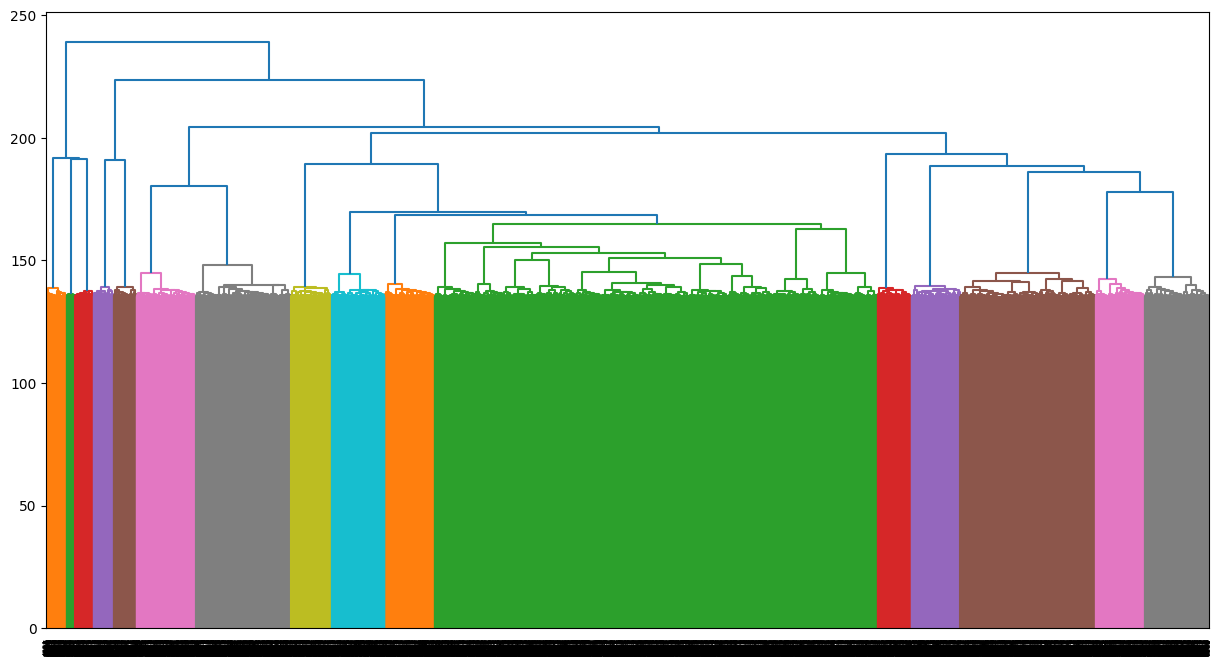

In [ ]:
#dendograms
plt.figure(
figsize=(15,8)
)

dendrogram(
linkage(
scaled,
method='ward'
)
)

plt.show()

In [ ]:
#model
model=AgglomerativeClustering(
n_clusters=5
)

cluster=model.fit_predict(
scaled)

auto['Cluster']=cluster

In [ ]:
#intrepretation
auto.groupby(
'Cluster'
).mean()

,Customer Lifetime Value,Effective To Date,Income,Monthly Premium Auto,Months Since Last Claim,Months Since Policy Inception,Number of Open Complaints,Number of Policies,Total Claim Amount,Customer_AA11235,...,Sales Channel_Branch,Sales Channel_Call Center,Sales Channel_Web,Vehicle Class_Luxury Car,Vehicle Class_Luxury SUV,Vehicle Class_SUV,Vehicle Class_Sports Car,Vehicle Class_Two-Door Car,Vehicle Size_Medsize,Vehicle Size_Small
Cluster,,,,,,,,,,,,,,,,,,,,,
0,8017.857748,2011-03-26 15:18:59.030022912,18870.351424,98.330639,15.234026,48.018091,0.309854,3.042340,526.565686,0.000385,...,0.268283,0.177829,0.150500,0.000000,0.000000,0.194765,0.162818,0.177059,0.717090,0.170516
1,8549.383043,2011-03-22 12:46:12.192513280,39073.901070,91.478610,14.804813,46.280749,0.401070,2.885027,429.291048,0.000000,...,0.288770,0.152406,0.165775,0.008021,0.016043,0.197861,0.066845,0.184492,0.689840,0.213904
2,17108.041917,2011-03-31 11:47:13.136094720,37498.875740,213.115385,15.328402,51.263314,0.387574,2.926036,1112.261001,0.000000,...,0.275148,0.171598,0.168639,0.473373,0.526627,0.000000,0.000000,0.000000,0.668639,0.230769
3,6860.492389,2011-04-02 07:38:40.000000000,40409.009053,84.605761,15.178601,47.523457,0.344856,3.018930,377.799214,0.000000,...,0.289712,0.207407,0.120988,0.000000,0.000000,0.199177,0.009877,0.236214,0.705350,0.200000
4,7587.599521,2011-03-30 04:40:33.846821376,47418.557388,83.957475,15.004990,48.143632,0.435235,2.918854,347.455908,0.000000,...,0.285745,0.203081,0.144934,0.000000,0.000000,0.211326,0.005207,0.232154,0.698633,0.199609


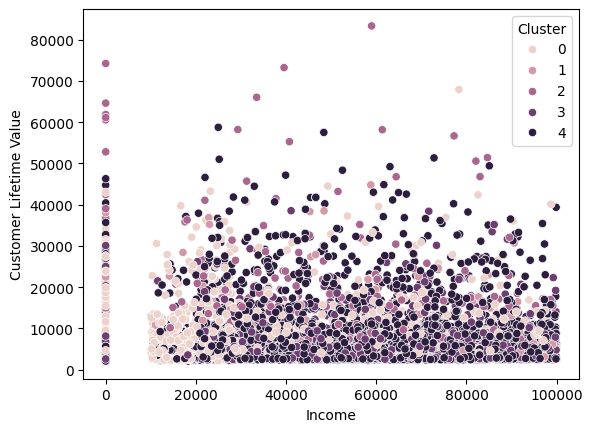

In [ ]:
#visualization
sns.scatterplot(
x='Income',
y='Customer Lifetime Value',
hue='Cluster',
data=auto
)

plt.show()

In [ ]:
'''Business Decisions

High Value → premium offers

Medium → upselling

Low → retention strategy'''

'Business Decisions\n\nHigh Value → premium offers\n\nMedium → upselling\n\nLow → retention strategy'

In [ ]:
#model evaluation for all assignments
score=silhouette_score(
scaled,
cluster
)

print(
"Silhouette Score:",
score
)

Silhouette Score: 0.00018527364930667986


In [ ]:
'''Interpretation
Score	    Interpretation
>0.7	    Excellent
0.5–0.7	  Good
0.25–0.5	Average
<0.25	    Weak'''

'Interpretation\nScore\t    Interpretation\n>0.7\t    Excellent\n0.5–0.7\t  Good\n0.25–0.5\tAverage\n<0.25\t    Weak'